Setup stuff

In [26]:
import numpy as np
import pandas as pd
import bambi as bmb
import arviz as az

In [27]:
df = pd.read_csv("domestic_well_radon.csv")
df = df.dropna(subset=["log_radon", "well_depth_ft", "lithology", "aquifer"])
df["log_depth"] = np.log(df["well_depth_ft"])
df["centered_log_depth"] = (df["log_depth"] - df["log_depth"].mean())
df = df[["log_radon", "centered_log_depth", "lithology", "aquifer"]]
df.dropna()
df.head()

,log_radon,centered_log_depth,lithology,aquifer
0,5.950643,-1.004532,Unconsolidated sand and gravel (non-glacial),Surficial
1,5.880533,-0.229892,Unconsolidated sand and gravel (non-glacial),Surficial
2,6.865891,-0.880480,Unconsolidated sand and gravel (non-glacial),Surficial
3,7.259820,-1.103623,Unconsolidated sand and gravel (non-glacial),Surficial
4,7.028201,-1.062801,Unconsolidated sand and gravel (non-glacial),Surficial


Priors (change later):

In [28]:
hierarchical_priors = {
    "Intercept": bmb.Prior("Normal", mu=6.0, sigma=2.0),
    "centered_log_depth": bmb.Prior("Normal", mu=0.0, sigma=1.0),
    "sigma": bmb.Prior("HalfNormal", sigma=1.0),
    "1|lithology": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0)),
    "1|aquifer": bmb.Prior("Normal", mu=0.0, sigma=bmb.Prior("HalfNormal", sigma=1.0))
}
pooled_priors = {
    "Intercept": bmb.Prior("Normal", mu=6.0, sigma=2.0),
    "centered_log_depth": bmb.Prior("Normal", mu=0.0, sigma=1.0),
    "sigma": bmb.Prior("HalfNormal", sigma=1.0),
}

Model. Hierarchical, with intercept from lithology & aquifer

In [32]:
hierarchical_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth + (1 | lithology) + (1 | aquifer)",
    ),
    data=df,
    priors=hierarchical_priors,
)

pooled_model = bmb.Model(
    formula = bmb.Formula(
        "log_radon ~ 1 + centered_log_depth",
    ),
    data=df,
    priors=pooled_priors,
)

In [33]:
hierarchical_fit = hierarchical_model.fit(target_accept=0.95, idata_kwargs={"log_likelihood": True})


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth, 1|lithology_sigma, 1|lithology_offset, 1|aquifer_sigma, 1|aquifer_offset]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 47 seconds.


In [31]:
pooled_fit =  pooled_model.fit(idata_kwargs={"log_likelihood": True})

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [sigma, Intercept, centered_log_depth]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.


Summary statistics:

Hierarchical model analysis
Divergences: 0
                     mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  \
Intercept           6.094  0.297   5.531    6.660      0.007    0.007   
centered_log_depth -0.113  0.034  -0.177   -0.050      0.000    0.001   
sigma               0.890  0.014   0.865    0.916      0.000    0.000   
1|lithology_sigma   0.791  0.248   0.381    1.238      0.006    0.008   
1|aquifer_sigma     0.457  0.076   0.321    0.600      0.002    0.001   

                    ess_bulk  ess_tail  r_hat  
Intercept             1623.0    1815.0    1.0  
centered_log_depth    5145.0    2934.0    1.0  
sigma                 4869.0    2773.0    1.0  
1|lithology_sigma     1609.0    2262.0    1.0  
1|aquifer_sigma       1229.0    2002.0    1.0  
                                                     mean     sd  hdi_3%  \
1|lithology[Basalt and other volcanic-rock aqui... -0.346  0.469  -1.164   
1|lithology[Carbonate-rock]                        -0.489  0.339  -1.132   
1|

<Axes: title={'center': 'Model comparison\nhigher is better'}, xlabel='elpd_loo (log)', ylabel='ranked models'>

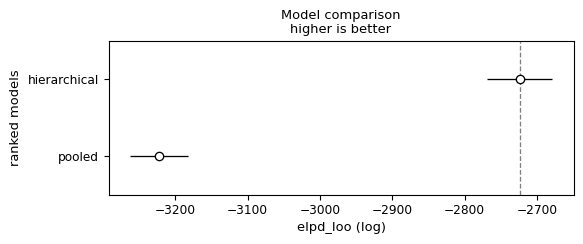

In [38]:
print("Hierarchical model analysis")
print("Divergences:", int(hierarchical_fit.sample_stats["diverging"].sum()))
print(
    az.summary(
        hierarchical_fit,
        var_names=["Intercept", "centered_log_depth", "sigma", "1|lithology_sigma", "1|aquifer_sigma"],
    )
)

print(az.summary(hierarchical_fit, var_names=["1|lithology"]))

print("Pooled model analysis")
print("Divergences:", int(pooled_fit.sample_stats["diverging"].sum()))
print(
    az.summary(
        pooled_fit,
        var_names=["Intercept", "centered_log_depth", "sigma"],
    )
)


print("LOO: hierarchical")
hierarchical_loo = az.loo(hierarchical_fit, pointwise=True)
print(hierarchical_loo)

print("LOO: pooled")
pooled_loo = az.loo(pooled_fit, pointwise=True)
print(pooled_loo)

print("Model comparison")
comparison = az.compare(
    {"hierarchical": hierarchical_fit, "pooled": pooled_fit},
    ic="loo",
)
print(comparison)

az.plot_compare(comparison)
